# Olist — слой Silver

Silver превращает строки из Bronze в очищенные таблицы с правильными типами и помечает проблемы
качества флагами. Ноутбук показывает, что изменилось «до» (Bronze) и «после» (Silver), и проверяет
отчёт о качестве.

**Данные:** `data/bronze/olist/`, `data/silver/olist/` и отчёт `_quality.json`, созданные скриптом
`python -m src.transformations.olist.silver`. Правила слоя — в [silver.md](../../../docs/architecture/silver.md).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics.db import q
from src.analytics import style as st

st.apply_style()
pd.set_option("display.float_format", lambda v: st.num(v, 2))
pd.set_option("display.max_columns", 30)

In [2]:
import json

import pyarrow.parquet as pq

from src.utils.config import BRONZE_DIR, RAW_DIR, SILVER_DIR

BRONZE, SILVER = BRONZE_DIR / "olist", SILVER_DIR / "olist"
quality = json.loads((SILVER / "_quality.json").read_text(encoding="utf-8"))
bronze = lambda name, cols=None: pd.read_parquet(BRONZE / name, columns=cols)
silver = lambda name, cols=None: pd.read_parquet(SILVER / name, columns=cols)
quality["status"], quality["errors"]

('OK', [])

## Отчёт о качестве

**Вопрос:** прошли ли все жёсткие проверки — разбор типов, первичные ключи, сохранность строк, ссылочная целостность?

In [3]:
report = pd.DataFrame([{
    "таблица": name,
    "строк в Bronze": t["rows_in"],
    "строк в Silver": t["rows_out"],
    "ошибок разбора": sum(t["parse_failures"].values()),
    "дубликатов ключа": t["duplicate_keys"],
    "пустых ключей": t["null_keys"],
} for name, t in quality["tables"].items()])
report

,таблица,строк в Bronze,строк в Silver,ошибок разбора,дубликатов ключа,пустых ключей
0,category_translation,71,74,0,0,0
1,products,32951,32951,0,0,0
2,customers,99441,99441,0,0,0
3,sellers,3095,3095,0,0,0
4,orders,99441,99441,0,0,0
5,order_items,112650,112650,0,0,0
6,payments,103886,103886,0,0,0
7,reviews,99224,99224,0,0,0
8,geolocation,1000163,19010,0,0,0


In [4]:
pd.DataFrame(quality["foreign_keys"]).rename(columns={"child": "ссылка", "parent": "на что", "orphans": "висячих"})

,ссылка,на что,висячих
0,orders.customer_id,customers.customer_id,0
1,order_items.order_id,orders.order_id,0
2,order_items.product_id,products.product_id,0
3,order_items.seller_id,sellers.seller_id,0
4,payments.order_id,orders.order_id,0
5,reviews.order_id,orders.order_id,0
6,products.product_category_name,category_translation.product_category_name,0


In [5]:
pd.DataFrame(quality["zip_coverage"])

,column,rows,missing_in_geolocation,coverage_pct
0,customers.customer_zip_code_prefix,99441,279,"99,72"
1,sellers.seller_zip_code_prefix,3095,7,"99,77"


**Формула**

$$\text{ошибок разбора}_c = \left|\{\, i : x^{\text{bronze}}_{i,c} \ne \text{NULL},\ x^{\text{silver}}_{i,c} = \text{NULL} \,\}\right|$$

$$\text{покрытие} = \frac{\left|\{\, i : z_i \in Z_{\text{geo}} \,\}\right|}{n}$$

где $x_{i,c}$ — значение колонки $c$ в строке $i$ до и после приведения типа, $z_i$ — почтовый индекс строки,
$Z_{\text{geo}}$ — индексы, которые есть в геолокации.

**Пример расчёта** (покрытие индексов покупателей)

$$\frac{99\,441 - 279}{99\,441} = \frac{99\,162}{99\,441} \approx 0{,}9972 \;(99{,}72\%)$$

**Вывод.**
- Все жёсткие проверки пройдены: 0 ошибок разбора типов, ключи уникальны, ни одной висячей ссылки.
- Число строк сохранено во всех таблицах, кроме двух намеренных изменений: геолокация сжата до одной строки
  на индекс (1 000 163 → 19 010), а в справочник категорий добавлены 3 строки.
- 0,3% покупателей и продавцов имеют индекс, которого нет в геолокации. В Gold они получают регион
  `unknown`, но не теряются.

## Типы данных

**Вопрос:** как меняются типы колонок между слоями?

In [6]:
def types(layer, name):
    schema = pq.read_schema(next((layer / name).glob("*.parquet")))
    return pd.Series({n: str(t) for n, t in zip(schema.names, schema.types)})

pd.concat({"Bronze": types(BRONZE, "order_items"), "Silver": types(SILVER, "order_items")}, axis=1).fillna("—")

,Bronze,Silver
order_id,string,string
order_item_id,string,int32
product_id,string,string
seller_id,string,string
shipping_limit_date,string,timestamp[us]
price,string,"decimal128(12, 2)"
freight_value,string,"decimal128(12, 2)"
_source,string,—
_source_file,string,—
_ingestion_timestamp,timestamp[ns],—


In [7]:
pd.concat({"Bronze": types(BRONZE, "orders"), "Silver": types(SILVER, "orders")}, axis=1).fillna("—")

,Bronze,Silver
order_id,string,string
customer_id,string,string
order_status,string,string
order_purchase_timestamp,string,timestamp[us]
order_approved_at,string,timestamp[us]
order_delivered_carrier_date,string,timestamp[us]
order_delivered_customer_date,string,timestamp[us]
order_estimated_delivery_date,string,date32[day]
_source,string,—
_source_file,string,—


**Вывод.**
- Деньги стали `decimal(12,2)`: сумма в таком типе считается точно до копейки, без ошибок округления `float`.
- Дата и время — `timestamp` без часового пояса. Olist записывает местное бразильское время; тип с поясом
  сдвинул бы значения на часовой пояс того, кто читает данные.
- Обещанная дата доставки — `date`: время в ней всегда 00:00.
- Технические поля Bronze, кроме `_batch_id`, отброшены, а флаги качества добавлены как логические колонки.

## Ведущие нули в почтовых индексах

**Вопрос:** что произойдёт, если прочитать индексы как числа?

In [8]:
naive = pd.read_csv(RAW_DIR / "olist" / "olist_geolocation_dataset.csv", usecols=["geolocation_zip_code_prefix"])
as_text = naive.geolocation_zip_code_prefix.astype(str)
pd.DataFrame({
    "чтение": ["pandas по умолчанию (число)", "Bronze и Silver (строка)"],
    "тип": [str(naive.geolocation_zip_code_prefix.dtype), "string"],
    "индексов короче 5 символов": [int((as_text.str.len() < 5).sum()), int((silver("geolocation", ["zip_code_prefix"]).zip_code_prefix.str.len() < 5).sum())],
    "пример": [as_text[as_text.str.len() < 5].iloc[0], "01037"],
})

,чтение,тип,индексов короче 5 символов,пример
0,pandas по умолчанию (число),int64,245733,1037
1,Bronze и Silver (строка),string,0,01037


**Вывод.** При чтении по умолчанию pandas считает индекс числом, и у 245 733 строк геолокации пропадает
ведущий ноль: `01037` превращается в `1037`. Такой индекс уже не совпадёт с индексом покупателя,
и соединение молча потеряет строки. Поэтому индексы везде читаются как строки длиной 5 символов.

## Очистка названий городов

**Вопрос:** насколько грязные названия городов и что с ними делает очистка?

In [9]:
cities = bronze("sellers", ["seller_id", "seller_city"]).merge(
    silver("sellers", ["seller_id", "seller_city"]), on="seller_id", suffixes=("_bronze", "_silver"))
changed = cities[cities.seller_city_bronze != cities.seller_city_silver]
pd.DataFrame({
    "уникальных городов в Bronze": [cities.seller_city_bronze.nunique()],
    "уникальных городов в Silver": [cities.seller_city_silver.nunique()],
    "продавцов с изменённым городом": [len(changed)],
    "стали пустыми": [int(cities.seller_city_silver.isna().sum())],
})

,уникальных городов в Bronze,уникальных городов в Silver,продавцов с изменённым городом,стали пустыми
0,611,586,30,2


In [10]:
(changed.drop_duplicates("seller_city_bronze")
        .sort_values("seller_city_bronze")
        .head(15)[["seller_city_bronze", "seller_city_silver"]]
        .rename(columns={"seller_city_bronze": "было", "seller_city_silver": "стало"}))

,было,стало
517,04482255,None
237,auriflama/sp,auriflama
1447,barbacena/ minas gerais,barbacena
2162,carapicuiba / sao paulo,carapicuiba
622,cariacica / es,cariacica
191,ferraz de vasconcelos,ferraz de vasconcelos
3015,jacarei / sao paulo,jacarei
78,lages - sc,lages
1159,maua/sao paulo,maua
1337,mogi das cruzes / sp,mogi das cruzes


**Вывод.**
- Город продавца — свободный текст: встречаются диакритика (`são paulo`), приписанный штат
  (`sao paulo - sp`, `mogi das cruzes / sp`), полное название штата, e-mail и просто число.
- После очистки уникальных городов 586 вместо 611. Ещё два значения — e-mail и число — стали пустыми.
- Город по-прежнему остаётся вводом продавца, поэтому для географии в Gold используется почтовый индекс
  и справочник геолокации, а не текст города.

## Агрегация геолокации

**Вопрос:** как миллион точек превращается в справочник «индекс → координаты, город, штат, регион»?

In [11]:
geo = silver("geolocation")
pd.DataFrame({
    "строк в Bronze": [quality["tables"]["geolocation"]["source_rows"]],
    "точек вне Бразилии": [quality["tables"]["geolocation"]["rows_outside_brazil"]],
    "индексов в Bronze": [quality["tables"]["geolocation"]["source_zip_prefixes"]],
    "строк в Silver": [len(geo)],
    "медиана точек на индекс": [geo.points_count.median()],
    "индексов с несколькими вариантами города": [int((geo.city_variants > 1).sum())],
})

,строк в Bronze,точек вне Бразилии,индексов в Bronze,строк в Silver,медиана точек на индекс,индексов с несколькими вариантами города
0,1000163,42,19015,19010,"29,00",543


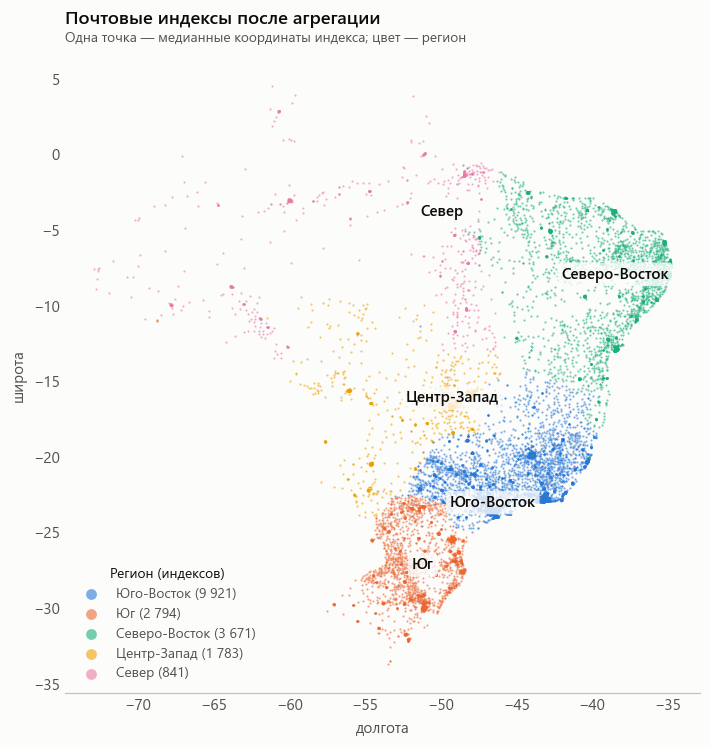

In [12]:
regions = ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"]
names_ru = {"Sudeste": "Юго-Восток", "Sul": "Юг", "Nordeste": "Северо-Восток", "Centro-Oeste": "Центр-Запад", "Norte": "Север"}
fig, ax = plt.subplots(figsize=(7.5, 7.5))
for color, region in zip(st.SERIES, regions):
    part = geo[geo.region == region]
    ax.scatter(part.lng, part.lat, s=2, color=color, alpha=0.6, linewidth=0, label=f"{names_ru[region]} ({st.num(len(part))})", rasterized=True)
    ax.text(part.lng.median(), part.lat.median(), names_ru[region], fontsize=10, fontweight="semibold", color=st.INK,
            ha="center", va="center", bbox=dict(boxstyle="round,pad=0.25", fc=st.SURFACE, ec="none", alpha=0.8))
ax.set_aspect("equal")
ax.grid(False)
ax.set_xlabel("долгота")
ax.set_ylabel("широта")
ax.legend(loc="lower left", markerscale=5, title="Регион (индексов)", title_fontsize=9)
st.titles(ax, "Почтовые индексы после агрегации", "Одна точка — медианные координаты индекса; цвет — регион")
st.save(fig, "olist_silver_01_zip_centroids")
plt.show()

**Формула**

$$\hat{\varphi}_z = \operatorname{median}\{\, \varphi_i : z_i = z,\ i \in B \,\}, \qquad \hat{\lambda}_z = \operatorname{median}\{\, \lambda_i : z_i = z,\ i \in B \,\}$$

$$\hat{c}_z = \arg\max_{c}\ \left|\{\, i : z_i = z,\ c_i = c \,\}\right|$$

где $\varphi_i$ и $\lambda_i$ — широта и долгота точки $i$, $B$ — точки внутри прямоугольника Бразилии
($-34 \le \varphi \le 6$, $-74 \le \lambda \le -34$), $\hat{c}_z$ — самый частый город индекса $z$
(при равенстве — первый по алфавиту).

**Пример расчёта**

$$1\,000\,163 - 42 = 1\,000\,121 \text{ точек} \;\rightarrow\; 19\,010 \text{ индексов}, \qquad \frac{1\,000\,121}{19\,010} \approx 52{,}6 \text{ точки на индекс}$$

**Вывод.**
- Миллион строк сведён к 19 010 индексам: по одной строке, с медианными координатами, самым частым городом
  и штатом, регионом и числом исходных точек. 5 индексов состояли только из ошибочных точек и исчезли.
- Медиана выбрана вместо среднего, потому что устойчива к оставшимся неточным точкам внутри страны.
- Карта индексов повторяет карту населения Бразилии: плотный Юго-Восток и Юг, побережье Северо-Востока
  и редкие точки на Севере.

## Флаги качества

**Вопрос:** сколько строк помечено каждым флагом?
Строки не удаляются: флаг позволяет исключить их там, где это важно, и сохранить везде, где не мешает.

In [13]:
flags = pd.DataFrame([
    {"таблица": name, "флаг": flag, "строк": count, "доля": count / t["rows_out"]}
    for name, t in quality["tables"].items() for flag, count in t["flags"].items()
    if flag not in ("is_valid_order", "is_latest_for_order", "has_title", "has_comment", "is_manual")
]).sort_values("доля", ascending=False)
st.as_pct(flags, ["доля"], 2)

,таблица,флаг,строк,доля
0,products,is_category_missing,610,"1,85%"
2,orders,is_timestamp_inconsistent,189,"0,19%"
1,products,has_invalid_measurements,6,"0,02%"
3,orders,has_status_date_conflict,14,"0,01%"
4,order_items,is_shipping_limit_outlier,12,"0,01%"


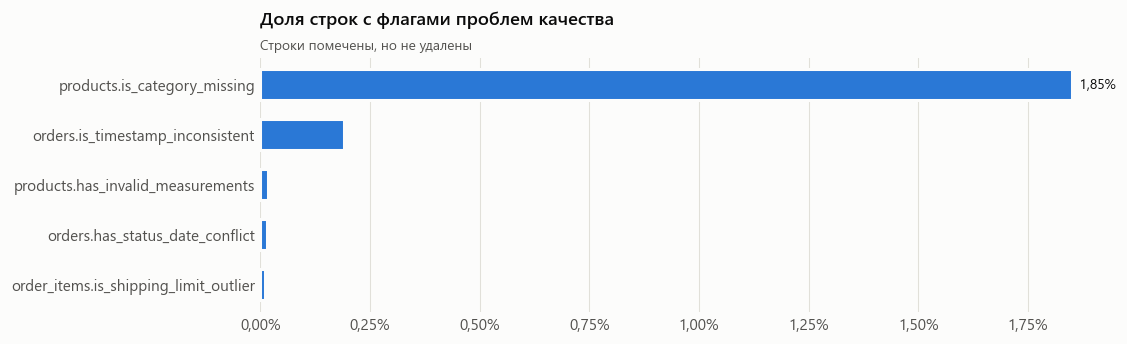

In [14]:
fig, ax = plt.subplots(figsize=(10, 3))
labels = flags["таблица"] + "." + flags["флаг"]
st.hbar(ax, labels, flags["доля"], fmt=lambda v: st.pct(v, 2))
st.percent_axis(ax, "x", decimals=2)
st.titles(ax, "Доля строк с флагами проблем качества", "Строки помечены, но не удалены")
st.save(fig, "olist_silver_02_quality_flags")
plt.show()

**Формула** (флаг нарушенного порядка дат)

$$\mathrm{inconsistent}_o = \mathbb{1}\left[\, t^{\mathrm{appr}}_o < t^{\mathrm{purch}}_o \;\lor\; t^{\mathrm{carr}}_o < t^{\mathrm{purch}}_o \;\lor\; t^{\mathrm{deliv}}_o < t^{\mathrm{carr}}_o \;\lor\; t^{\mathrm{deliv}}_o < t^{\mathrm{purch}}_o \,\right]$$

где $t^{\mathrm{purch}}, t^{\mathrm{appr}}, t^{\mathrm{carr}}, t^{\mathrm{deliv}}$ — покупка, подтверждение оплаты,
передача перевозчику и доставка заказа $o$; сравнение с пустой датой считается ложным.

**Пример расчёта**

$$166 + 23 = 189 \text{ заказов}, \qquad \frac{189}{99\,441} \approx 0{,}0019 \;(0{,}19\%)$$

**Вывод.**
- Проблем немного: товары без категории — 1,85%, заказы с нарушенным порядком дат — 0,19%,
  остальные флаги — сотые доли процента.
- Каждый флаг используется в Gold по назначению: заказы с противоречивыми датами исключаются из логистики,
  выбросы срока отгрузки — из метрик продавцов, товары без категории получают категорию `unknown`.

## Отзывы: последний отзыв на заказ

**Вопрос:** как выбрать один отзыв, если у заказа их несколько?

In [15]:
rv = silver("reviews", ["review_id", "order_id", "review_score", "review_creation_date", "review_answer_timestamp", "is_latest_for_order"])
multi = rv.groupby("order_id").size()
example = rv[rv.order_id == multi[multi > 1].index[0]].sort_values("review_answer_timestamp")
example

,review_id,order_id,review_score,review_creation_date,review_answer_timestamp,is_latest_for_order
24855,2a74b0559eb58fc1ff842ecc999594cb,0035246a40f520710769010f752e7507,5,2017-08-25,2017-08-29 21:45:57,False
24854,89a02c45c340aeeb1354a24e7d4b2c1e,0035246a40f520710769010f752e7507,5,2017-08-29,2017-08-30 01:59:12,True


**Вывод.** У 547 заказов несколько отзывов. Флаг `is_latest_for_order` отмечает один — с самым поздним
ответом покупателя. Ровно один отзыв на заказ нужен, чтобы при соединении с заказами не размножить строки
и не завысить выручку.

## Справочник категорий

**Вопрос:** что добавлено в справочник перевода вручную?

In [16]:
silver("category_translation").query("is_manual")

,product_category_name,product_category_name_english,is_manual
60,pc_gamer,pc_gamer,True
65,portateis_cozinha_e_preparadores_de_alimentos,portable_kitchen_and_food_preparers,True
72,unknown,unknown,True


**Вывод.** Две категории товаров не имели перевода, а 610 товаров — категории вообще. Ручные строки
справочника закрывают оба случая, поэтому у каждого товара в Gold есть английское название категории.

## Итоги

| Что сделано в Silver | Результат |
|---|---|
| Приведение типов | 0 ошибок разбора; деньги — `decimal`, время — без часового пояса |
| Ключи и связи | ключи уникальны, 0 висячих ссылок |
| Почтовые индексы | строки длиной 5, ведущие нули сохранены |
| Названия городов | 611 → 586 вариантов у продавцов |
| Геолокация | 1 000 163 точки → 19 010 индексов с регионом |
| Флаги качества | 5 видов проблем помечены, строки сохранены |
| Отзывы | один последний отзыв на заказ |
| Категории | у каждого товара есть категория и перевод |